## 1. Problem, stakeholders, hypotheses, baselines

**Stakeholder workflow.** A student asks a question about the course. LearnMate retrieves passages from the *approved course materials only*, selects one evidence sentence, and either (a) answers by citing that sentence or (b) abstains and tells the student what is missing. Instructors and TAs need confidence that every answer shown is traceable to the materials, and that questions the materials cannot answer are routed to office hours rather than answered plausibly.

**Failure mode (quantified in Section 5.1).** *Unsupported answer*: the system shows an answer whose cited evidence does not contain the answer, or the question has no answer in the materials.

**Proposed method (evidence agreement).** Per question we compute signals about whether *independent evidence views agree* that the cited sentence supports the question:
* retrieval agreement: lexical retriever and dense retriever pick the same paragraph;
* scorer agreement: reader, lexical similarity, and dense similarity pick the same sentence;
* support checks: question entities and numbers are actually present in the cited sentence and paragraph.

These are combined with the reader score by a logistic-regression calibrator fitted on **held-out calibration articles**, giving a probability that the answer is supported. The system abstains below a threshold chosen on separate validation articles.

**Baselines (two main + one stronger control).**
* **B1 – Sentence-Transformer-style semantic search:** dense sentence retrieval; abstain if cosine similarity is below a threshold.
* **B2 – RAG with reader confidence:** lexical paragraph retrieval then a trained reader; abstain if the reader's top probability is below a threshold.
* **B2+ – stronger single-stage reader:** same as B2 but the reader also sees the support features (so any gain of LearnMate cannot be explained merely by those features).

**Pre-specified hypotheses (fixed before looking at test results)**
* **H1.** On held-out SQuAD 2.0 dev articles, LearnMate has lower AURC (area under the risk–coverage curve) than every baseline; article-cluster bootstrap 95% CI of the difference excludes 0.
* **H2.** At 20% coverage (read from the test risk–coverage curve), LearnMate's risk is at least 3 percentage points lower than B2's.
* **H3.** When half of the corpus paragraphs are removed (evidence missing), LearnMate's unsupported-answer rate at the same frozen thresholds is at least 20% lower (relative) than B2's, **while still answering at least 5% of questions** (otherwise abstaining on everything would trivially win).
* **H4.** Removing the agreement group from LearnMate increases AURC.

Results are reported against these hypotheses whether or not they hold.

**Deviations from the plan (disclosed).** H2 and the operating threshold were first specified at a **10%** risk target. A first full run showed that *no* method (including LearnMate) reached 10% risk at any non-trivial coverage, because a lexical evidence selector is too weak. A second run with a 30% risk target was also degenerate (coverage about 0 for every method). The **main operating point was therefore changed to a fixed 20% coverage**, and H2/H3 were rewritten accordingly (the 30%-risk results are still reported as a secondary operating point). In the same run, calibration data (train articles, 33% unanswerable) had a different base rate from the dev set (50% unanswerable), so calibration sets are now balanced to 50% unanswerable ("prior matching"). Both changes were made after seeing test-set behaviour, so the headline numbers should be read as *development-informed*, not as a clean pre-registered test.

In [1]:
import os, re, json, math, time, random, hashlib, platform, sys, warnings, urllib.request
from collections import defaultdict, Counter, OrderedDict
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
warnings.filterwarnings("ignore")

QUICK = os.environ.get("LEARNMATE_QUICK", "0") == "1"   # tiny smoke-test mode
SEED = 42
USE_SBERT = False          # True: use sentence-transformers/all-MiniLM-L6-v2 (needs internet + pip install sentence-transformers)
LAUNCH_UI = False          # True: launch the Gradio demo at the end
DATA_DIR, OUT_DIR, COURSE_DIR = "data", "outputs", "course_materials"
for d in (DATA_DIR, OUT_DIR, os.path.join(OUT_DIR, "figs")): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
RISK_TARGET = 0.30   # risk target for the secondary operating point (revised from 0.10; see deviations)
COV_TARGET = 0.20    # main operating point: answer the 20% most-confident questions (threshold set on validation articles)
K_PARAS = 3
print("QUICK mode:", QUICK, "| SBERT:", USE_SBERT)

QUICK mode: False | SBERT: False


## 2. Data acquisition and integrity check

SQuAD 2.0 (Rajpurkar et al., 2018) is downloaded from the official explorer; if that host is unreachable the identical files from the official GitHub repository are used. Counts are checked against the published figures (train 130,319 questions; dev 11,873).

In [2]:
SOURCES = {
 "train-v2.0.json": ["https://rajpurkar.github.io/SQuAD-explorer/dataset/train-v2.0.json",
                     "https://raw.githubusercontent.com/rajpurkar/SQuAD-explorer/master/dataset/train-v2.0.json"],
 "dev-v2.0.json":   ["https://rajpurkar.github.io/SQuAD-explorer/dataset/dev-v2.0.json",
                     "https://raw.githubusercontent.com/rajpurkar/SQuAD-explorer/master/dataset/dev-v2.0.json"],
}
def get_file(name):
    path = os.path.join(DATA_DIR, name)
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        return path
    for url in SOURCES[name]:
        try:
            print("downloading", url); urllib.request.urlretrieve(url, path)
            if os.path.getsize(path) > 1_000_000: return path
        except Exception as e:
            print("  failed:", e)
    raise RuntimeError(f"Could not obtain {name}. Download it manually into ./{DATA_DIR}/")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

train_raw = json.load(open(get_file("train-v2.0.json"), encoding="utf-8"))
dev_raw   = json.load(open(get_file("dev-v2.0.json"), encoding="utf-8"))
DATA_HASHES = {n: sha256(os.path.join(DATA_DIR, n)) for n in SOURCES}

def flatten(raw):
    paras, qs = [], []
    for art in raw["data"]:
        for p in art["paragraphs"]:
            pid = len(paras)
            paras.append(dict(pid=pid, article=art["title"], text=p["context"]))
            for q in p["qas"]:
                qs.append(dict(qid=q["id"], pid=pid, article=art["title"], question=q["question"],
                               impossible=bool(q.get("is_impossible", False)),
                               answers=[(a["text"], a["answer_start"]) for a in q["answers"]]))
    return paras, qs

P_train, Q_train = flatten(train_raw)
P_dev, Q_dev = flatten(dev_raw)
print("version:", train_raw.get("version"), dev_raw.get("version"))
print(f"train: {len(train_raw['data'])} articles, {len(P_train)} paragraphs, {len(Q_train)} questions")
print(f"dev  : {len(dev_raw['data'])} articles, {len(P_dev)} paragraphs, {len(Q_dev)} questions")
assert len(Q_train) == 130319 and len(Q_dev) == 11873, "counts differ from the published SQuAD 2.0 statistics"
print("sha256:", DATA_HASHES)

downloading https://rajpurkar.github.io/SQuAD-explorer/dataset/train-v2.0.json
downloading https://rajpurkar.github.io/SQuAD-explorer/dataset/dev-v2.0.json
version: v2.0 v2.0
train: 442 articles, 19035 paragraphs, 130319 questions
dev  : 35 articles, 1204 paragraphs, 11873 questions
sha256: {'train-v2.0.json': '68dcfbb971bd3e96d5b46c7177b16c1a4e7d4bdef19fb204502738552dede002', 'dev-v2.0.json': '80a5225e94905956a6446d296ca1093975c4d3b3260f1d6c8f68bc2ab77182d8'}


## 3. Dataset audit (Task 3)

### 3.1 SQuAD 2.0 audit
Checks: label integrity (answer offsets), answerable share, split disjointness, duplicates across train/dev, and a **construction artifact check**: in SQuAD 2.0 the unanswerable questions were written by crowd-workers to look like answerable ones, often by swapping an entity. If named entities in the question are systematically missing from the paragraph for unanswerable questions, any feature that detects this may exploit a dataset artifact rather than a general property of evidence. This matters for how we interpret gains (and is why Section 7 tests a different domain).

In [3]:
TOK = re.compile(r"[A-Za-z0-9]+(?:'[a-z]+)?")
STOP = set(ENGLISH_STOP_WORDS)
def stem(t):
    t = t.lower()
    if t.endswith("'s"): t = t[:-2]
    if len(t) > 4 and t.endswith("s") and not t.endswith("ss"): t = t[:-1]
    return t
def tok_list(text):
    return [(stem(t), t.lower() in STOP, t) for t in TOK.findall(text)]
def entities_of(question):
    lst = tok_list(question)
    nums = [s for s, stp, raw in lst if raw.isdigit()]
    ents = [s for i, (s, stp, raw) in enumerate(lst) if i > 0 and raw[0].isupper() and not stp and not raw.isdigit()]
    return list(dict.fromkeys(ents)), list(dict.fromkeys(nums))

def audit(paras, qs, raw, name):
    bad = 0; n_ans = 0
    for q in qs:
        for t, s in q["answers"]:
            n_ans += 1
            if paras[q["pid"]]["text"][s:s+len(t)] != t: bad += 1
    imp = np.mean([q["impossible"] for q in qs])
    ent_miss = {True: [], False: []}
    for q in qs:
        ents, _ = entities_of(q["question"])
        if not ents: continue
        ptoks = {s for s, _, _ in tok_list(paras[q["pid"]]["text"])}
        ent_miss[q["impossible"]].append(np.mean([e not in ptoks for e in ents]))
    return dict(split=name, articles=len(raw["data"]), paragraphs=len(paras), questions=len(qs),
                unanswerable_share=round(float(imp), 4), answer_offset_mismatches=bad, answers_checked=n_ans,
                mean_q_words=round(float(np.mean([len(q["question"].split()) for q in qs])), 2),
                mean_para_words=round(float(np.mean([len(p["text"].split()) for p in paras])), 1),
                entity_missing_rate_answerable=round(float(np.mean(ent_miss[False])), 4),
                entity_missing_rate_unanswerable=round(float(np.mean(ent_miss[True])), 4))

audit_df = pd.DataFrame([audit(P_train, Q_train, train_raw, "train"), audit(P_dev, Q_dev, dev_raw, "dev")])
tr_titles = {a["title"] for a in train_raw["data"]}; dv_titles = {a["title"] for a in dev_raw["data"]}
tr_q = {q["question"].strip().lower() for q in Q_train}; dv_q = {q["question"].strip().lower() for q in Q_dev}
tr_p = {p["text"] for p in P_train}; dv_p = {p["text"] for p in P_dev}
leak = dict(shared_article_titles=len(tr_titles & dv_titles), shared_question_texts=len(tr_q & dv_q), shared_paragraphs=len(tr_p & dv_p))
print(audit_df.T.to_string()); print("train/dev overlap:", leak)
audit_df.to_csv(f"{OUT_DIR}/audit_squad.csv", index=False)
json.dump(leak, open(f"{OUT_DIR}/audit_leakage.json", "w"))

# manual label-audit sample for a second human checker (Task 3: "independently checked")
rs = np.random.default_rng(SEED)
samp = rs.choice(len(Q_dev), 40, replace=False)
pd.DataFrame([dict(qid=Q_dev[i]["qid"], question=Q_dev[i]["question"], squad_label="unanswerable" if Q_dev[i]["impossible"] else "answerable",
                   paragraph_start=P_dev[Q_dev[i]["pid"]]["text"][:300], checker_label="") for i in samp]
             ).to_csv(f"{OUT_DIR}/label_audit_sample_for_human_check.csv", index=False)

                                       0       1
split                              train     dev
articles                             442      35
paragraphs                         19035    1204
questions                         130319   11873
unanswerable_share                0.3338  0.5007
answer_offset_mismatches               0       0
answers_checked                    86821   20302
mean_q_words                        9.89   10.02
mean_para_words                    116.6   126.6
entity_missing_rate_answerable    0.0859  0.0682
entity_missing_rate_unanswerable  0.1307  0.1222
train/dev overlap: {'shared_article_titles': 0, 'shared_question_texts': 9, 'shared_paragraphs': 0}


### 3.2 Split strategy and leakage controls
All splits are **by article** (never by question), so no paragraph seen in training can appear in calibration or test:

| Split | Source | Use |
|---|---|---|
| reader-train | train articles | fits reader models |
| calibration-fit (70% of cal articles) | train articles disjoint from reader-train | fits LearnMate's calibrator and Platt scalers of baselines |
| calibration-val (30% of cal articles) | train articles disjoint from the above | picks abstention thresholds (fixed 20% coverage; a 30%-risk threshold is also reported) |
| test | official **dev** articles | reported once; never used to tune anything |
| shift | course materials | out-of-domain test |

The frozen dense encoder is fitted without labels on train articles excluding all calibration articles.

In [4]:
train_arts = [a["title"] for a in train_raw["data"]]
perm = np.random.default_rng(SEED).permutation(len(train_arts))
n_cal, n_rt = (10, 20) if QUICK else (45, 120)
cal_arts = [train_arts[i] for i in perm[:n_cal]]
n_fit = int(round(0.7 * n_cal))
cal_fit_arts, cal_val_arts = set(cal_arts[:n_fit]), set(cal_arts[n_fit:])
rt_arts = set(train_arts[i] for i in perm[n_cal:n_cal + n_rt])
bg_arts = set(train_arts) - set(cal_arts)          # unlabeled background for the frozen encoder
assert not (rt_arts & set(cal_arts)) and not (cal_fit_arts & cal_val_arts)
dev_titles = [a["title"] for a in dev_raw["data"]]
test_arts = set(dev_titles[:8] if QUICK else dev_titles)

def subset(paras, qs, arts, max_q=None, seed=SEED, balance=False):
    ps = [p for p in paras if p["article"] in arts]
    keep = {p["pid"] for p in ps}
    qq = [q for q in qs if q["pid"] in keep]
    if balance:   # prior matching: keep all unanswerable, downsample answerable to a 50/50 mix (dev is 50.1% unanswerable)
        un = [q for q in qq if q["impossible"]]; an = [q for q in qq if not q["impossible"]]
        ii = np.random.default_rng(seed).choice(len(an), min(len(an), len(un)), replace=False); qq = un + [an[i] for i in sorted(ii)]
    if max_q and len(qq) > max_q:
        ii = np.random.default_rng(seed).choice(len(qq), max_q, replace=False); qq = [qq[i] for i in sorted(ii)]
    return ps, qq

P_rt, Q_rt = subset(P_train, Q_train, rt_arts, max_q=3000 if QUICK else 40000)
P_cf, Q_cf = subset(P_train, Q_train, cal_fit_arts, balance=True)
P_cv, Q_cv = subset(P_train, Q_train, cal_val_arts, balance=True)
P_te, Q_te = subset(P_dev, Q_dev, test_arts)
for n, (p, q) in dict(reader_train=(P_rt, Q_rt), cal_fit=(P_cf, Q_cf), cal_val=(P_cv, Q_cv), test=(P_te, Q_te)).items():
    print(f"{n:12s} paragraphs={len(p):6d} questions={len(q):6d} unanswerable={np.mean([x['impossible'] for x in q]):.3f}")

reader_train paragraphs=  5414 questions= 37149 unanswerable=0.325
cal_fit      paragraphs=  1337 questions=  5784 unanswerable=0.500
cal_val      paragraphs=   536 questions=  3332 unanswerable=0.500
test         paragraphs=  1204 questions= 11873 unanswerable=0.501


## 4. Pipeline: encoder, index, evidence features, readers

* **Lexical retriever:** TF-IDF (1–2 grams) over paragraphs, top-3 paragraphs.
* **Dense retriever:** frozen encoder (LSA stand-in or Sentence-Transformer) over paragraphs and sentences.
* **Candidates:** all sentences of the top-3 paragraphs. The reader scores each; the best sentence is the *citation*.
* **Gold support** (for evaluation only): the cited sentence is in the gold paragraph and contains the start of a gold answer; unanswerable questions are never supported.

In [5]:
def l2(Z):
    n = np.linalg.norm(Z, axis=1, keepdims=True); return (Z / np.maximum(n, 1e-9)).astype(np.float32)

class LSAEncoder:
    name = "LSA-256 (frozen; stand-in for a Sentence-Transformer)"
    def __init__(self, dim): self.dim = dim
    def fit(self, texts):
        self.vec = TfidfVectorizer(stop_words="english", sublinear_tf=True, min_df=3, max_features=60000, dtype=np.float32)
        X = self.vec.fit_transform(texts)
        self.svd = TruncatedSVD(n_components=self.dim, n_iter=4, random_state=SEED).fit(X); return self
    def encode(self, texts): return l2(self.svd.transform(self.vec.transform(texts)))

class SBERTEncoder:
    name = "sentence-transformers/all-MiniLM-L6-v2"
    def __init__(self):
        from sentence_transformers import SentenceTransformer
        self.m = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    def encode(self, texts): return self.m.encode(list(texts), batch_size=64, normalize_embeddings=True, show_progress_bar=False).astype(np.float32)

t0 = time.time()
if USE_SBERT:
    ENCODER = SBERTEncoder()
else:
    bg_paras = [p["text"] for p in P_train if p["article"] in bg_arts]
    if QUICK: bg_paras = bg_paras[:3000]
    ENCODER = LSAEncoder(64 if QUICK else 256).fit(bg_paras)
print("encoder:", ENCODER.name, f"({time.time()-t0:.0f}s)")

encoder: LSA-256 (frozen; stand-in for a Sentence-Transformer) (7s)


In [6]:
_SENT_RE = re.compile(r'(?<=[.!?])["”\')\]]?\s+(?=[A-Z0-9"“(\[])')
def split_sentences(text):
    out, start = [], 0
    for m in _SENT_RE.finditer(text):
        out.append((start, m.start() + len(m.group(0).rstrip()))); start = m.end()
    out.append((start, len(text)))
    return [(s, e) for s, e in out if e > s]

MONTHS = {"january","february","march","april","may","june","july","august","september","october","november","december","century","decade"}
NUMW = {"one","two","three","four","five","six","seven","eight","nine","ten","hundred","thousand","million","billion","half","dozen"}
WH = [("how many","howmany"),("how much","howmuch"),("when","when"),("who","who"),("whom","who"),("whose","who"),
      ("where","where"),("why","why"),("how","how"),("which","which"),("what","what")]
def wh_type(q):
    ql = q.lower()
    for key, name in WH:
        if re.search(r"\b" + key + r"\b", ql): return name
    return "other"
def type_ok(wh, s):
    sl = s.lower()
    if wh == "when": return int(bool(re.search(r"\b(1\d{3}|20\d{2})\b", s)) or any(m in sl for m in MONTHS))
    if wh in ("howmany", "howmuch"): return int(bool(re.search(r"\d", s)) or any(w in sl.split() for w in NUMW))
    if wh == "who": return int(bool(re.search(r"[a-z,;] [A-Z][a-z]+", s)))
    return 1

class Index:
    def __init__(self, paras, encoder):
        self.paras, self.encoder = paras, encoder
        self.sents, self.para_sents = [], [[] for _ in paras]
        for row, p in enumerate(paras):
            for k, (s, e) in enumerate(split_sentences(p["text"])):
                sid = len(self.sents)
                self.sents.append(dict(sid=sid, row=row, pid=p["pid"], k=k, start=s, end=e, text=p["text"][s:e]))
                self.para_sents[row].append(sid)
        self.vec = TfidfVectorizer(stop_words="english", sublinear_tf=True, ngram_range=(1, 2), dtype=np.float32)
        self.P = self.vec.fit_transform([p["text"] for p in paras])
        self.S = self.vec.transform([s["text"] for s in self.sents])
        self.Pl = encoder.encode([p["text"] for p in paras]); self.Sl = encoder.encode([s["text"] for s in self.sents])
        self.sent_toks, self.sent_big = [], []
        ptoks = [set() for _ in paras]
        for s in self.sents:
            lst = tok_list(s["text"]); ts = frozenset(t for t, _, _ in lst)
            cs = [t for t, stp, _ in lst if not stp]
            self.sent_toks.append(ts); self.sent_big.append(frozenset(zip(cs, cs[1:]))); ptoks[s["row"]] |= ts
        self.para_toks = ptoks
        df = Counter()
        for pt in ptoks: df.update(pt)
        self.N = len(paras); self.df = df
    def idf(self, t): return math.log((self.N + 1) / (self.df.get(t, 0) + 1)) + 1.0

def analyze(q, idx):
    lst = tok_list(q); seen, content = set(), []
    for s, stp, raw in lst:
        if not stp and s not in seen: content.append(s); seen.add(s)
    cs = [s for s, stp, _ in lst if not stp]
    ents, nums = entities_of(q)
    cw = [(t, idx.idf(t)) for t in content]
    return dict(cw=cw, totw=sum(w for _, w in cw), big=frozenset(zip(cs, cs[1:])), ent=ents, num=nums,
                wh=wh_type(q), qlen=len(lst))

def gold_flag(q, s):
    if q["impossible"] or s["pid"] != q["pid"]: return 0
    return int(any(s["start"] <= a < s["end"] for _, a in q["answers"]))

PAIR_COLS = ["qi","sid","r","para_score","k","is_first","cov","big","cos_t","cos_d","type_ok","ent_miss_s","ent_miss_p","num_miss_s","qlen","n_ent","gold"]

def featurize(idx, qs, K=K_PARAS, chunk=1000):
    texts = [q["question"] for q in qs]; nQ = len(qs)
    Q = idx.vec.transform(texts); Ql = idx.encoder.encode(texts)
    K = min(K, len(idx.paras)); rows = []; qlev = []
    b1_conf = np.zeros(nQ); b1_sid = np.zeros(nQ, int)
    for c0 in range(0, nQ, chunk):
        c1 = min(nQ, c0 + chunk)
        Sp = (Q[c0:c1] @ idx.P.T).toarray(); Dp = Ql[c0:c1] @ idx.Pl.T; Ds = Ql[c0:c1] @ idx.Sl.T
        b1_sid[c0:c1] = Ds.argmax(1); b1_conf[c0:c1] = Ds.max(1)
        for i in range(c1 - c0):
            qi = c0 + i; sp = Sp[i]
            top = np.argpartition(-sp, K - 1)[:K] if K < len(sp) else np.arange(len(sp))
            top = top[np.argsort(-sp[top])]
            s1 = float(sp[top[0]]); s2 = float(sp[top[1]]) if len(top) > 1 else 0.0
            dense_rank = int((Dp[i] > Dp[i, top[0]]).sum())
            qlev.append((qi, s1, min(s1 / (s2 + 1e-3), 50.0), dense_rank))
            qa = analyze(qs[qi]["question"], idx)
            for r, row in enumerate(top):
                pt = idx.para_toks[row]; nsent = len(idx.para_sents[row])
                ent_p = (sum(e not in pt for e in qa["ent"]) / len(qa["ent"])) if qa["ent"] else 0.0
                for sid in idx.para_sents[row]:
                    ss = idx.sent_toks[sid]; st = idx.sents[sid]
                    cov = (sum(w for t, w in qa["cw"] if t in ss) / qa["totw"]) if qa["totw"] > 0 else 0.0
                    big = len(qa["big"] & idx.sent_big[sid]) / len(qa["big"]) if qa["big"] else 0.0
                    ent_s = (sum(e not in ss for e in qa["ent"]) / len(qa["ent"])) if qa["ent"] else 0.0
                    num_s = (sum(n not in ss for n in qa["num"]) / len(qa["num"])) if qa["num"] else 0.0
                    rows.append((qi, sid, r, float(sp[row]), st["k"], int(st["k"] == 0), cov, big, 0.0, 0.0,
                                 type_ok(qa["wh"], st["text"]), ent_s, ent_p, num_s, qa["qlen"], min(len(qa["ent"]), 5),
                                 gold_flag(qs[qi], st)))
    pairs = pd.DataFrame(rows, columns=PAIR_COLS)
    qi_a, sid_a = pairs["qi"].values, pairs["sid"].values
    pairs["cos_t"] = np.asarray(Q[qi_a].multiply(idx.S[sid_a]).sum(1)).ravel()
    pairs["cos_d"] = (Ql[qi_a] * idx.Sl[sid_a]).sum(1)
    ql = pd.DataFrame(qlev, columns=["qi","para_score_top1","para_ratio","dense_rank"]).set_index("qi")
    b1_gold = np.array([gold_flag(qs[i], idx.sents[b1_sid[i]]) for i in range(nQ)])
    return pairs, ql, b1_conf, b1_gold

READER_BASE = ["cov","big","cos_t","para_score","r","k","is_first","type_ok","qlen"]
READER_PLUS = READER_BASE + ["cos_d","ent_miss_s","ent_miss_p","num_miss_s"]

def fit_readers(idx, qs):
    pairs, _, _, _ = featurize(idx, qs)
    mk = lambda: HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=SEED)
    r1 = mk().fit(pairs[READER_BASE], pairs["gold"]); r2 = mk().fit(pairs[READER_PLUS], pairs["gold"])
    return r1, r2, pairs

t0 = time.time()
idx_rt = Index(P_rt, ENCODER)
READER, READER_PLUS_M, rt_pairs = fit_readers(idx_rt, Q_rt)
print(f"reader trained on {len(Q_rt)} questions / {len(rt_pairs)} candidate sentences ({time.time()-t0:.0f}s); positive rate {rt_pairs.gold.mean():.4f}")

reader trained on 37149 questions / 544049 candidate sentences (53s); positive rate 0.0384


In [ ]:
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def score_questions(idx, qs, K=K_PARAS):
    pairs, ql, b1_conf, b1_gold = featurize(idx, qs, K)
    d = pairs.copy()
    d["p1"] = READER.predict_proba(d[READER_BASE])[:, 1]
    d["p2"] = READER_PLUS_M.predict_proba(d[READER_PLUS])[:, 1]
    def ranked(col):
        o = d.sort_values(["qi", col], ascending=[True, False], kind="stable"); o["rk"] = o.groupby("qi").cumcount(); return o
    o1 = ranked("p1"); best = o1[o1.rk == 0].set_index("qi")
    sec = o1[o1.rk == 1].set_index("qi")["p1"].reindex(best.index).fillna(0.0)
    o2 = ranked("p2"); best2 = o2[o2.rk == 0].set_index("qi")
    bt = ranked("cos_t").query("rk==0").set_index("qi")["sid"]; bd = ranked("cos_d").query("rk==0").set_index("qi")["sid"]
    Z = pd.DataFrame(index=best.index)
    Z["qid"] = [qs[i]["qid"] for i in Z.index]; Z["article"] = [qs[i]["article"] for i in Z.index]
    Z["pid_gold"] = [qs[i]["pid"] for i in Z.index]; Z["impossible"] = [qs[i]["impossible"] for i in Z.index]
    Z["reader_p"] = best["p1"]; Z["reader_logit"] = logit(best["p1"].values); Z["margin"] = best["p1"] - sec
    Z["best_sid"] = best["sid"]; Z["gold_b"] = best["gold"]
    Z["plus_p"] = best2["p2"]; Z["gold_plus"] = best2["gold"]
    Z["para_score_top1"] = ql["para_score_top1"]; Z["para_ratio"] = ql["para_ratio"]; Z["para_score_b"] = best["para_score"]
    Z["agree_count"] = (bt.reindex(Z.index) == best["sid"]).astype(int) + (bd.reindex(Z.index) == best["sid"]).astype(int)
    Z["agree_para"] = (ql["dense_rank"] == 0).astype(int); Z["log_dense_rank"] = np.log1p(ql["dense_rank"])
    Z["b_in_top1"] = (best["r"] == 0).astype(int); Z["cos_d_b"] = best["cos_d"]
    Z["cov_b"] = best["cov"]; Z["ent_miss_s"] = best["ent_miss_s"]; Z["ent_miss_p"] = best["ent_miss_p"]
    Z["num_miss_s"] = best["num_miss_s"]; Z["type_ok_b"] = best["type_ok"]; Z["n_ent"] = best["n_ent"]
    Z["b1_conf"] = b1_conf[Z.index]; Z["gold_b1"] = b1_gold[Z.index]
    return Z

GROUPS = OrderedDict(reader=["reader_logit"], margin=["margin"],
                     retrieval=["para_score_top1", "para_ratio", "para_score_b"],
                     agreement=["agree_count", "agree_para", "log_dense_rank", "b_in_top1", "cos_d_b"],
                     support=["cov_b", "ent_miss_s", "ent_miss_p", "num_miss_s", "type_ok_b", "n_ent"])
ALL = list(GROUPS)
VARIANTS = OrderedDict([
    ("LearnMate (full)", ALL),
    ("Abl: - agreement", [g for g in ALL if g != "agreement"]),
    ("Abl: - support", [g for g in ALL if g != "support"]),
    ("Abl: - margin", [g for g in ALL if g != "margin"]),
    ("Abl: - retrieval", [g for g in ALL if g != "retrieval"]),
    ("Abl: - reader score", [g for g in ALL if g != "reader"]),
    ("Abl: reader only (calibrated)", ["reader"]),
    ("Abl: reader+margin+retrieval", ["reader", "margin", "retrieval"]),
    ("Abl: reader+agreement", ["reader", "agreement"]),
    ("Abl: reader+support", ["reader", "support"]),
])
def cols_of(groups): return [c for g in groups for c in GROUPS[g]]

t0 = time.time()
Z_cf = score_questions(Index(P_cf, ENCODER), Q_cf)
Z_cv = score_questions(Index(P_cv, ENCODER), Q_cv)
print(f"calibration sets scored ({time.time()-t0:.0f}s): fit={len(Z_cf)}, val={len(Z_cv)}")

CAL = OrderedDict()
for name, groups in VARIANTS.items():
    CAL[name] = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000)).fit(Z_cf[cols_of(groups)], Z_cf["gold_b"])
CAL["LearnMate-GBM (nonlinear)"] = HistGradientBoostingClassifier(max_depth=3, max_iter=150, learning_rate=0.08, random_state=SEED).fit(Z_cf[cols_of(ALL)], Z_cf["gold_b"])

PLATT = {}   # 1-D recalibration of baseline scores, fitted on cal-fit only (used for ECE / Brier)
def base_feat(name, Z):
    return {"B1": Z["b1_conf"].values, "B2": Z["reader_logit"].values, "B2+": logit(Z["plus_p"].values)}[name]
for nm, y in [("B1", "gold_b1"), ("B2", "gold_b"), ("B2+", "gold_plus")]:
    PLATT[nm] = LogisticRegression(max_iter=1000).fit(base_feat(nm, Z_cf).reshape(-1, 1), Z_cf[y])

BASE_NAMES = {"B1": "B1 Dense sentence search", "B2": "B2 RAG + reader confidence", "B2+": "B2+ RAG + reader (support feats)"}
def methods_for(Z):
    M = OrderedDict()
    M[BASE_NAMES["B1"]] = (Z["b1_conf"].values, Z["gold_b1"].values)
    M[BASE_NAMES["B2"]] = (Z["reader_p"].values, Z["gold_b"].values)
    M[BASE_NAMES["B2+"]] = (Z["plus_p"].values, Z["gold_plus"].values)
    for name, model in CAL.items():
        cols = cols_of(ALL) if "GBM" in name else cols_of(VARIANTS[name])
        M[name] = (model.predict_proba(Z[cols])[:, 1], Z["gold_b"].values)
    return M
def prob_for(Z, name, conf):
    # a probability for ECE / Brier: LR/GBM outputs are probabilities already; baselines get Platt scaling
    for k, v in BASE_NAMES.items():
        if name == v: return PLATT[k].predict_proba(base_feat(k, Z).reshape(-1, 1))[:, 1]
    return conf

calibration sets scored (4s): fit=5784, val=3332


## 5. Metrics and main held-out evaluation (SQuAD 2.0 dev, unseen articles)

* **Supported** (label): the cited sentence lies in the gold paragraph and contains a gold answer.
* **Risk** = share of *answered* questions that are unsupported. **Coverage** = share of questions answered.
* **AURC** = mean risk over all coverage levels (lower is better). **Risk@20%cov** = risk when the 20% most-confident questions are answered. **Cov@30%** = largest coverage with risk ≤ 30%.
* **ECE / Brier** measure whether the confidence is a trustworthy probability; baseline scores are first Platt-scaled on calibration-fit data so the comparison is fair.
* Main operating point: the threshold for every method is picked on **calibration-val** articles so that 20% of questions are answered, then frozen. A secondary threshold targets 30% risk (`*_riskthr` columns); it is often so strict that nothing is answered.

In [ ]:
def rc_curve(conf, y):
    order = np.argsort(-np.asarray(conf), kind="stable"); yy = np.asarray(y, float)[order]
    k = np.arange(1, len(yy) + 1); return k / len(yy), 1 - np.cumsum(yy) / k
def aurc(conf, y): return float(rc_curve(conf, y)[1].mean())
def cov_at_risk(conf, y, r):
    cov, risk = rc_curve(conf, y); ok = np.where(risk <= r)[0]; return float(cov[ok.max()]) if len(ok) else 0.0
def pick_threshold(conf, y, r):
    conf = np.asarray(conf); order = np.argsort(-conf, kind="stable"); cov, risk = rc_curve(conf, y)
    ok = np.where(risk <= r)[0]
    return float(conf[order][ok.max()]) if len(ok) else float("inf")
def ece(prob, y, bins=10):
    prob = np.asarray(prob); y = np.asarray(y, float); b = np.minimum((prob * bins).astype(int), bins - 1); e = 0.0
    for i in range(bins):
        m = b == i
        if m.any(): e += m.mean() * abs(prob[m].mean() - y[m].mean())
    return float(e)

M_cv = methods_for(Z_cv)
def risk_at_cov(conf, y, cov):
    _, risk = rc_curve(conf, y); return float(risk[max(0, int(round(cov * len(risk))) - 1)])
TAU = {n: float(np.quantile(c, 1 - COV_TARGET)) for n, (c, y) in M_cv.items()}          # main: fixed coverage
TAU_R = {n: pick_threshold(c, y, RISK_TARGET) for n, (c, y) in M_cv.items()}            # secondary: risk target

def metrics_table(Z, M, extra=None):
    rows = []
    for name, (conf, y) in M.items():
        y = np.asarray(y).astype(int); prob = prob_for(Z, name, conf); ans = conf >= TAU[name]; ansr = conf >= TAU_R[name]
        rows.append(OrderedDict(method=name, AURC=aurc(conf, y), cov_at_10pct_risk=cov_at_risk(conf, y, .10),
            cov_at_20pct_risk=cov_at_risk(conf, y, .20), cov_at_30pct_risk=cov_at_risk(conf, y, .30), risk_at_20pct_cov=risk_at_cov(conf, y, .20), risk_at_40pct_cov=risk_at_cov(conf, y, .40), AUROC=roc_auc_score(y, conf) if 0 < y.mean() < 1 else np.nan,
            ECE=ece(prob, y), Brier=brier_score_loss(y, prob), tau=TAU[name], coverage=ans.mean(),
            risk=(1 - y[ans].mean()) if ans.any() else np.nan, unsupported_answer_rate=float(((y == 0) & ans).mean()),
            supported_kept=float(((y == 1) & ans).sum() / max(1, y.sum())),
            coverage_riskthr=ansr.mean(), risk_riskthr=(1 - y[ansr].mean()) if ansr.any() else np.nan))
    return pd.DataFrame(rows)

t0 = time.time()
idx_te = Index(P_te, ENCODER)
Z_te = score_questions(idx_te, Q_te); M_te = methods_for(Z_te)
print(f"test set scored: {len(Z_te)} questions ({time.time()-t0:.0f}s)")
T_main = metrics_table(Z_te, M_te)
MAIN = ["B1 Dense sentence search", "B2 RAG + reader confidence", "B2+ RAG + reader (support feats)", "LearnMate (full)", "LearnMate-GBM (nonlinear)"]
pd.set_option("display.width", 220, "display.max_columns", 30)
print(T_main[T_main.method.isin(MAIN)].round(4).to_string(index=False))
T_main.to_csv(f"{OUT_DIR}/main_results_dev.csv", index=False)

test set scored: 11873 questions (4s)
                          method   AURC  cov_at_10pct_risk  cov_at_20pct_risk  cov_at_30pct_risk  risk_at_20pct_cov  risk_at_40pct_cov  AUROC    ECE  Brier    tau  coverage   risk  unsupported_answer_rate  supported_kept  coverage_riskthr  risk_riskthr
        B1 Dense sentence search 0.8694             0.0000             0.0000             0.0000             0.8577             0.8728 0.6149 0.0127 0.0838 0.8222    0.2524 0.8622                   0.2176          0.3711            0.0013        0.6250
      B2 RAG + reader confidence 0.5098             0.0000             0.0000             0.0000             0.4236             0.4856 0.7156 0.0193 0.1970 0.6057    0.2132 0.4311                   0.0919          0.3554            0.0395        0.3326
B2+ RAG + reader (support feats) 0.5027             0.0001             0.0001             0.0138             0.4160             0.4757 0.7182 0.0163 0.1973 0.6325    0.2056 0.4170                   0.085

### 5.1 Task 1: quantifying the failure mode
If the tutor always answered (no abstention), what share of answers would be unsupported? This is the application-relevant failure that abstention must reduce.

In [ ]:
y_all = Z_te["gold_b"].values; imp = Z_te["impossible"].values
fm = OrderedDict(
    n_questions=len(Z_te),
    share_unanswerable=float(imp.mean()),
    always_answer_unsupported_rate=float(1 - y_all.mean()),
    unsupported_among_unanswerable=1.0,
    unsupported_among_answerable=float(1 - y_all[~imp].mean()),
    top20pct_most_confident_B2_unsupported=float(1 - y_all[np.argsort(-Z_te["reader_p"].values)[: int(0.2 * len(Z_te))]].mean()))
for k, v in fm.items(): print(f"{k:45s} {v:.4f}" if isinstance(v, float) else f"{k:45s} {v}")
json.dump(fm, open(f"{OUT_DIR}/failure_mode.json", "w"), indent=1)

n_questions                                   11873
share_unanswerable                            0.5007
always_answer_unsupported_rate                0.6587
unsupported_among_unanswerable                1.0000
unsupported_among_answerable                  0.3165
top20pct_most_confident_B2_unsupported        0.4238


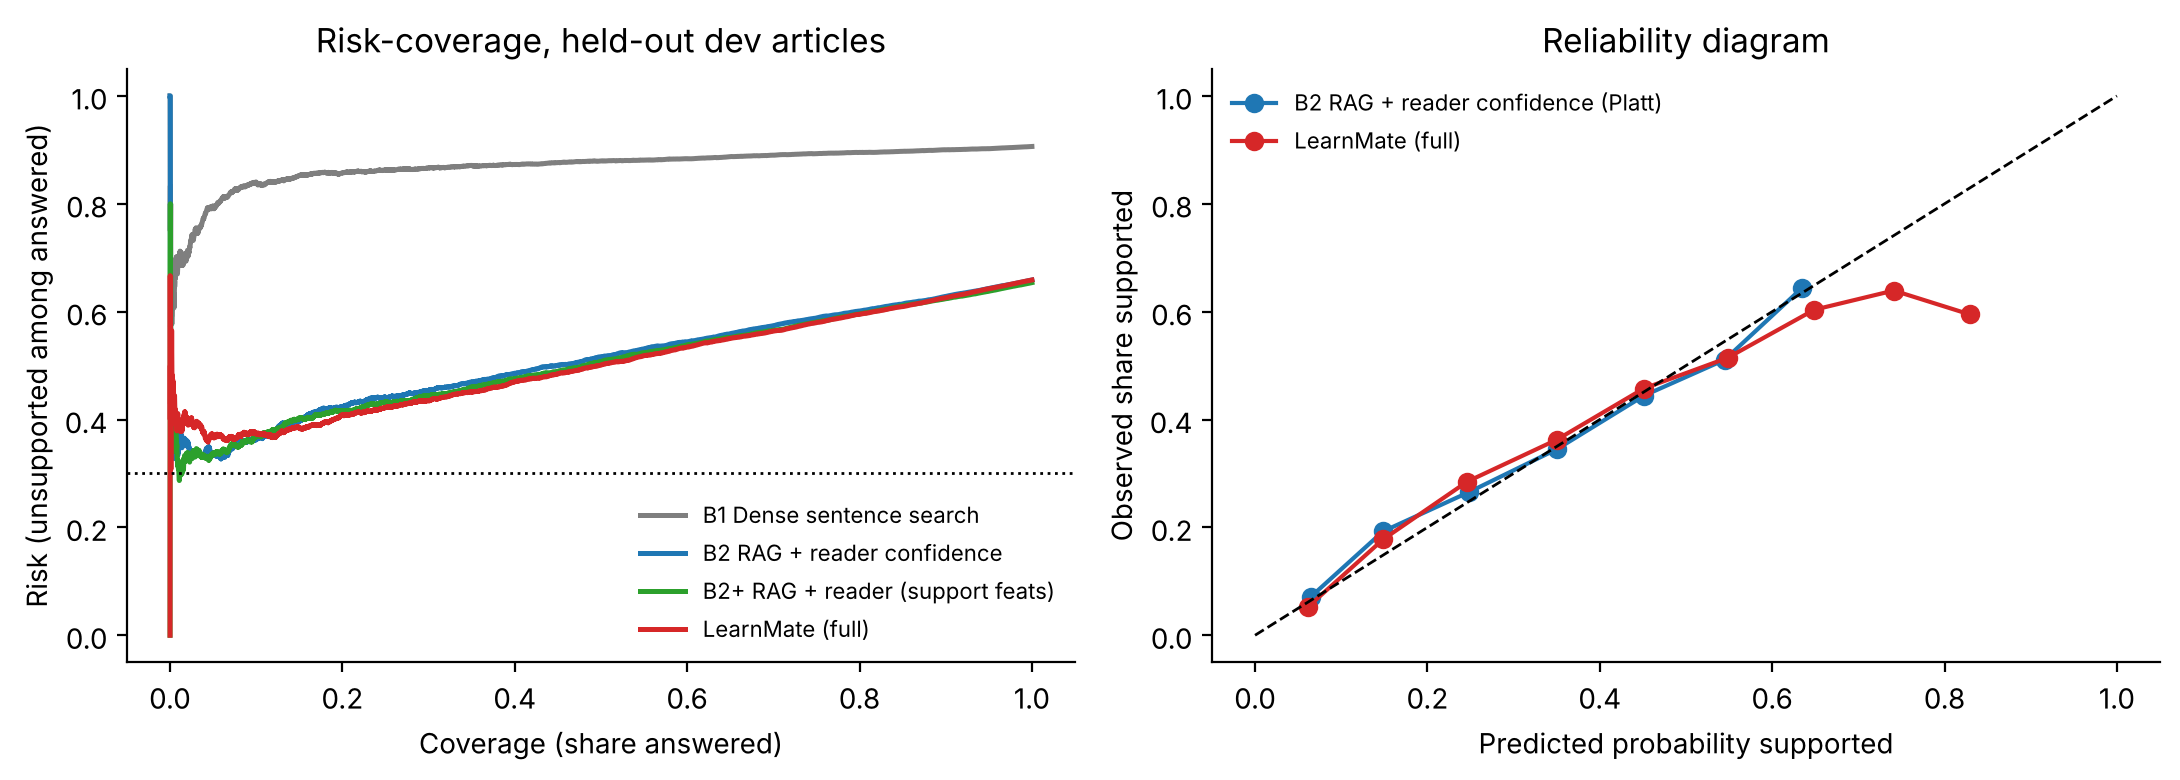

In [ ]:
COL = {"B1 Dense sentence search": "#7f7f7f", "B2 RAG + reader confidence": "#1f77b4",
       "B2+ RAG + reader (support feats)": "#2ca02c", "LearnMate (full)": "#d62728"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for n, c in COL.items():
    cov, risk = rc_curve(*[M_te[n][0], M_te[n][1]]); ax[0].plot(cov, risk, color=c, label=n, lw=1.8)
ax[0].axhline(RISK_TARGET, color="k", ls=":", lw=1); ax[0].set(xlabel="Coverage (share answered)", ylabel="Risk (unsupported among answered)", title="Risk-coverage, held-out dev articles")
ax[0].legend(frameon=False, fontsize=8)
for n in ["B2 RAG + reader confidence", "LearnMate (full)"]:
    p = prob_for(Z_te, n, M_te[n][0]); y = M_te[n][1]; b = np.minimum((p * 10).astype(int), 9)
    xs = [p[b == i].mean() for i in range(10) if (b == i).sum() > 20]; ys = [y[b == i].mean() for i in range(10) if (b == i).sum() > 20]
    ax[1].plot(xs, ys, "o-", color=COL[n], label=n + (" (Platt)" if n.startswith("B2") else ""))
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set(xlabel="Predicted probability supported", ylabel="Observed share supported", title="Reliability diagram")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figs/fig1_risk_coverage_reliability.png", dpi=160); plt.show()

## 6. Ablation and statistical test

Each ablation removes one feature group from the calibrator (or keeps only some groups). **"reader only (calibrated)"** isolates the effect of calibration alone from the effect of evidence-agreement features. Uncertainty comes from a **cluster bootstrap over articles** (1,000 resamples), because questions from the same article are not independent.

                       method   AURC  risk_at_20pct_cov  cov_at_30pct_risk  AUROC    ECE  Brier  coverage   risk  unsupported_answer_rate
             LearnMate (full) 0.5023             0.4076             0.0001 0.7349 0.0310 0.1931    0.1927 0.4021                   0.0775
             Abl: - agreement 0.5016             0.4025             0.0003 0.7337 0.0284 0.1932    0.1978 0.4012                   0.0793
               Abl: - support 0.5091             0.4105             0.0000 0.7242 0.0326 0.1961    0.1935 0.4095                   0.0793
                Abl: - margin 0.5064             0.4131             0.0007 0.7284 0.0235 0.1943    0.2028 0.4140                   0.0840
             Abl: - retrieval 0.5012             0.4046             0.0000 0.7341 0.0283 0.1928    0.1951 0.4035                   0.0788
          Abl: - reader score 0.5023             0.4067             0.0012 0.7352 0.0343 0.1934    0.1930 0.4020                   0.0776
Abl: reader only (calibrated) 0.50

               a                                b     metric   delta   ci_lo   ci_hi
LearnMate (full)         B1 Dense sentence search       AURC -0.3671 -0.3954 -0.3369
LearnMate (full)         B1 Dense sentence search RISK@20cov -0.4501 -0.4957 -0.4079
LearnMate (full)       B2 RAG + reader confidence       AURC -0.0075 -0.0127 -0.0022
LearnMate (full)       B2 RAG + reader confidence RISK@20cov -0.0160 -0.0335 -0.0074
LearnMate (full) B2+ RAG + reader (support feats)       AURC -0.0004 -0.0056  0.0045
LearnMate (full) B2+ RAG + reader (support feats) RISK@20cov -0.0084 -0.0243  0.0020
LearnMate (full)                 Abl: - agreement       AURC  0.0007 -0.0007  0.0021
LearnMate (full)                 Abl: - agreement RISK@20cov  0.0051 -0.0063  0.0117
LearnMate (full)    Abl: reader only (calibrated)       AURC -0.0075 -0.0127 -0.0022
LearnMate (full)    Abl: reader only (calibrated) RISK@20cov -0.0160 -0.0335 -0.0074


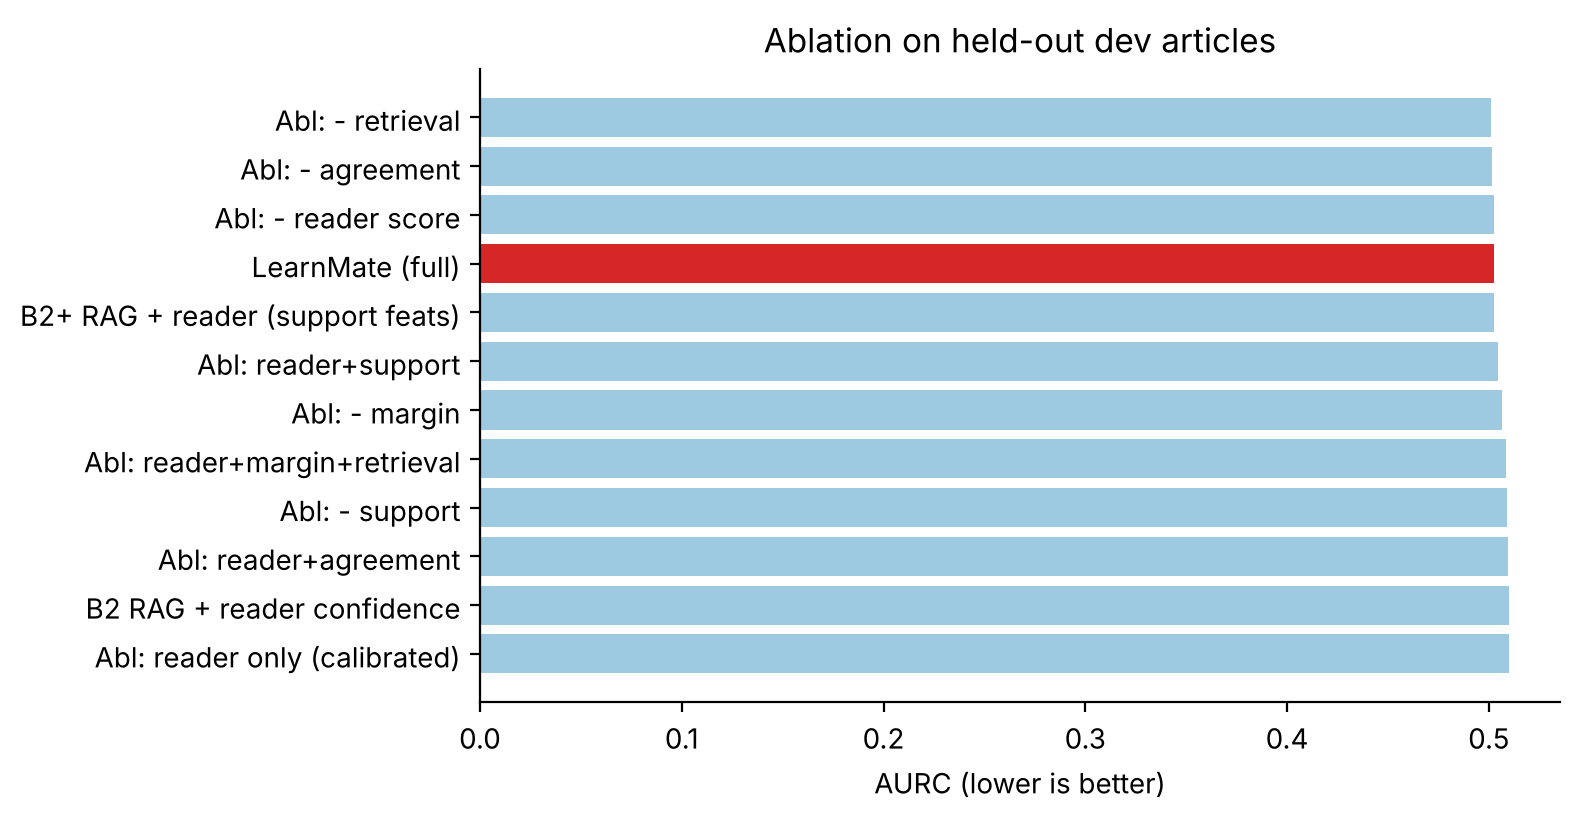

In [ ]:
abl_names = list(VARIANTS.keys())
T_abl = T_main[T_main.method.isin(abl_names)][["method", "AURC", "risk_at_20pct_cov", "cov_at_30pct_risk", "AUROC", "ECE", "Brier", "coverage", "risk", "unsupported_answer_rate"]].round(4)
print(T_abl.to_string(index=False)); T_abl.to_csv(f"{OUT_DIR}/ablation_dev.csv", index=False)

def boot_delta(Z, M, a, b, metric, cluster="article", B=1000, seed=SEED):
    rng = np.random.default_rng(seed); groups = defaultdict(list)
    for i, c in enumerate(Z[cluster].values): groups[c].append(i)
    garr = [np.array(v) for v in groups.values()]
    (ca, ya), (cb, yb) = M[a], M[b]; ya = np.asarray(ya).astype(int); yb = np.asarray(yb).astype(int)
    f = aurc if metric == "AURC" else (lambda c, y: risk_at_cov(c, y, COV_TARGET))
    ds = []
    for _ in range(B):
        pick = rng.integers(0, len(garr), len(garr)); ii = np.concatenate([garr[j] for j in pick])
        ds.append(f(ca[ii], ya[ii]) - f(cb[ii], yb[ii]))
    ds = np.array(ds)
    return OrderedDict(a=a, b=b, metric=metric, delta=f(ca, ya) - f(cb, yb), ci_lo=float(np.percentile(ds, 2.5)), ci_hi=float(np.percentile(ds, 97.5)))

LM = "LearnMate (full)"
rows = []
for b in ["B1 Dense sentence search", "B2 RAG + reader confidence", "B2+ RAG + reader (support feats)", "Abl: - agreement", "Abl: reader only (calibrated)"]:
    for metric in ("AURC", "RISK@20cov"): rows.append(boot_delta(Z_te, M_te, LM, b, metric))
T_boot = pd.DataFrame(rows); print(T_boot.round(4).to_string(index=False)); T_boot.to_csv(f"{OUT_DIR}/bootstrap_dev.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
sub = T_main[T_main.method.isin(abl_names + [BASE_NAMES["B2"], BASE_NAMES["B2+"]])].sort_values("AURC")
ax.barh(sub.method, sub.AURC, color=["#d62728" if m == LM else "#9ecae1" for m in sub.method]); ax.invert_yaxis()
ax.set(xlabel="AURC (lower is better)", title="Ablation on held-out dev articles"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figs/fig2_ablation.png", dpi=160); plt.show()

## 7. Stressed and out-of-domain conditions

**S2 – evidence missing.** Half of the test paragraphs are deleted from the corpus but all questions are still asked. Questions whose paragraph was deleted can no longer be answered from the corpus, so any answer is unsupported and the correct behaviour is to abstain. The models and thresholds are **not** re-tuned.

**S3 – domain shift.** Course materials (a different domain and tiny corpus), with the same frozen models and thresholds.

In [ ]:
rs = np.random.default_rng(SEED + 1)
pids_all = np.array([p["pid"] for p in P_te]); removed = set(rs.choice(pids_all, size=len(pids_all) // 2, replace=False).tolist())
P_s2 = [p for p in P_te if p["pid"] not in removed]
t0 = time.time(); Z_s2 = score_questions(Index(P_s2, ENCODER), Q_te); M_s2 = methods_for(Z_s2)
Z_s2["evidence_missing"] = Z_s2["pid_gold"].isin(removed).values
print(f"S2 corpus: {len(P_s2)} of {len(P_te)} paragraphs kept; {Z_s2.evidence_missing.mean():.3f} of questions have missing evidence ({time.time()-t0:.0f}s)")
T_s2 = metrics_table(Z_s2, M_s2)
miss_ans = (Z_s2.evidence_missing & ~Z_s2.impossible).values
T_s2["abstain_rate_on_missing_evidence_answerable"] = [float((M_s2[n][0][miss_ans] < TAU[n]).mean()) for n in T_s2.method]
print(T_s2[T_s2.method.isin(MAIN)][["method","AURC","risk_at_20pct_cov","coverage","risk","unsupported_answer_rate","supported_kept","abstain_rate_on_missing_evidence_answerable"]].round(4).to_string(index=False))
T_s2.to_csv(f"{OUT_DIR}/stress_s2_evidence_missing.csv", index=False)
T_boot2 = pd.DataFrame([boot_delta(Z_s2, M_s2, LM, b, "AURC") for b in ["B1 Dense sentence search", "B2 RAG + reader confidence", "B2+ RAG + reader (support feats)"]])
print(T_boot2.round(4).to_string(index=False)); T_boot2.to_csv(f"{OUT_DIR}/bootstrap_s2.csv", index=False)

S2 corpus: 602 of 1204 paragraphs kept; 0.500 of questions have missing evidence (4s)
                          method   AURC  risk_at_20pct_cov  coverage   risk  unsupported_answer_rate  supported_kept  abstain_rate_on_missing_evidence_answerable
        B1 Dense sentence search 0.9087             0.8964    0.1800 0.8919                   0.1605          0.3438                                       0.8601
      B2 RAG + reader confidence 0.6490             0.5179    0.1072 0.4580                   0.0491          0.3269                                       0.9868
B2+ RAG + reader (support feats) 0.6442             0.5065    0.1026 0.4433                   0.0455          0.3159                                       0.9878
                LearnMate (full) 0.6426             0.4973    0.1016 0.4303                   0.0437          0.3254                                       0.9929
       LearnMate-GBM (nonlinear) 0.6401             0.5053    0.1090 0.4312                   0.0470    

               a                                b metric   delta   ci_lo   ci_hi
LearnMate (full)         B1 Dense sentence search   AURC -0.2661 -0.2872 -0.2435
LearnMate (full)       B2 RAG + reader confidence   AURC -0.0064 -0.0104 -0.0017
LearnMate (full) B2+ RAG + reader (support feats)   AURC -0.0016 -0.0058  0.0028


### 7.1 Course materials (S3) and how to plug in your own

The demo course below ("DL-501") has 14 passages. Its 56 questions were **written by the notebook author** and include *answerable* questions, *near-miss* questions (the topic is in the materials but the fact is not), and *out-of-scope* questions. It is a pilot, **not an independently checked evaluation set**.

To use your approved materials: put `.txt`/`.md`/`.pdf` files in `course_materials/` and a `course_eval.csv` with columns `question, label, answer_text, source_file` (`label` = answerable/unanswerable; `answer_text` must be an exact substring of the source). Add `annotator_a`, `annotator_b` columns to compute Cohen's kappa. `course_eval_template.csv` is written for you to copy.

In [ ]:
DEMO_PASSAGES = [
 "DL-501 Applied Deep Learning is a 12-week course. Grading is based on four assignments worth 40% in total, a midterm exam worth 25%, and a final project worth 35%. Late assignments lose 10% of their marks per day, and no submission is accepted more than three days after the deadline. The lowest assignment score is not dropped.",
 "The perceptron is the simplest neural unit. It computes a weighted sum of its inputs, adds a bias term, and passes the result through an activation function. A single perceptron can only learn linearly separable functions, which is why it cannot represent the XOR function. Stacking units into multiple layers removes this limitation.",
 "Common activation functions include the sigmoid, the hyperbolic tangent, and the rectified linear unit (ReLU). ReLU outputs zero for negative inputs and the input itself for positive inputs. The sigmoid squashes values into the range between 0 and 1, but it can saturate and produce vanishing gradients in deep networks. For this reason, ReLU became the default choice for hidden layers in most modern architectures.",
 "Backpropagation computes the gradient of the loss with respect to every weight by applying the chain rule from the output layer back to the input layer. It reuses intermediate results from the forward pass, which makes the computation efficient. Automatic differentiation frameworks such as PyTorch build a computation graph during the forward pass and traverse it in reverse to obtain gradients.",
 "Gradient descent updates parameters in the direction opposite to the gradient of the loss. The learning rate controls the size of each update; a learning rate that is too large can cause divergence, while one that is too small makes training slow. Stochastic gradient descent estimates the gradient from a mini-batch rather than the full dataset. The Adam optimizer adds per-parameter adaptive learning rates and momentum.",
 "Overfitting occurs when a model fits the training data well but generalizes poorly to unseen data. Dropout randomly sets a fraction of activations to zero during training, which discourages co-adaptation of units. Weight decay adds a penalty proportional to the squared magnitude of the weights. Early stopping halts training when the validation loss stops improving.",
 "Batch normalization normalizes the activations of a layer using the mean and variance computed over the current mini-batch. It then applies a learnable scale and shift. It typically allows higher learning rates and speeds up convergence. At inference time, running averages of the mean and variance collected during training are used instead of batch statistics.",
 "Convolutional neural networks apply learnable filters that slide over the input and share weights across spatial positions. Pooling layers reduce spatial resolution and provide a degree of translation invariance. CNNs are the standard architecture for image classification tasks. Assignment 2 asks students to train a small CNN on the CIFAR-10 dataset.",
 "Recurrent neural networks process sequences by maintaining a hidden state that is updated at every time step. Training them with backpropagation through time can suffer from vanishing or exploding gradients. Long short-term memory (LSTM) units address this with input, forget, and output gates that control the flow of information. Gated recurrent units are a simpler variant with two gates.",
 "The Transformer architecture relies on self-attention instead of recurrence. Each token produces a query, a key, and a value vector, and attention weights are computed from the dot product of queries and keys. Multi-head attention runs several attention operations in parallel so the model can attend to different relationships. Positional encodings are added because self-attention by itself is unaware of token order.",
 "Sentence Transformers map sentences to dense vectors so that semantically similar sentences are close together. Similarity between two embeddings is commonly measured with cosine similarity. Bi-encoders embed queries and documents independently, which allows documents to be indexed in advance, while cross-encoders score a query and document jointly and are more accurate but slower. In Assignment 4, students build a semantic search tool over lecture notes.",
 "Retrieval-augmented generation (RAG) retrieves passages relevant to a question and conditions a language model on them. Grounding answers in retrieved text reduces hallucination, but the model can still produce unsupported claims when the retrieved passages are irrelevant. Good systems cite the passage they used and abstain when the evidence is inadequate. The final project may extend a RAG system built during the course.",
 "Precision is the fraction of predicted positives that are correct, and recall is the fraction of actual positives that are found. The F1 score is the harmonic mean of precision and recall. Accuracy can be misleading on imbalanced datasets. Calibration measures whether predicted probabilities match observed frequencies; the expected calibration error (ECE) averages the gap between confidence and accuracy over confidence bins.",
 "Lectures are held on Tuesdays and Thursdays, and a lab session takes place on Fridays. Office hours with the teaching assistants are on Wednesday afternoons. The midterm exam takes place in week 7 and is closed-book, but one handwritten A4 cheat sheet is allowed. The final project presentations are scheduled for week 12.",
]
# (question, answer_text or None, passage index, category)
DEMO_QA = [
 ("How much of the grade comes from the final project?", "35%", 0, "answerable"),
 ("How many assignments does DL-501 have?", "four assignments", 0, "answerable"),
 ("What penalty applies to a late assignment per day?", "10% of their marks per day", 0, "answerable"),
 ("Is the lowest assignment score dropped?", "is not dropped", 0, "answerable"),
 ("What percentage of the grade is the weekly quiz worth?", None, 0, "near-miss"),
 ("What is the passing grade for DL-501?", None, 0, "near-miss"),
 ("Who is the instructor of DL-501?", None, 0, "near-miss"),
 ("Why can a single perceptron not represent XOR?", "can only learn linearly separable functions", 1, "answerable"),
 ("What is added to the weighted sum of inputs before the activation function?", "a bias term", 1, "answerable"),
 ("Who invented the perceptron?", None, 1, "near-miss"),
 ("Which activation function became the default for hidden layers?", "became the default choice for hidden layers", 2, "answerable"),
 ("What range does the sigmoid squash values into?", "between 0 and 1", 2, "answerable"),
 ("What does ReLU output for negative inputs?", "outputs zero for negative inputs", 2, "answerable"),
 ("What is the derivative of the tanh function?", None, 2, "near-miss"),
 ("What rule does backpropagation apply?", "the chain rule", 3, "answerable"),
 ("What do automatic differentiation frameworks build during the forward pass?", "a computation graph", 3, "answerable"),
 ("How many layers did the first backpropagation experiments use?", None, 3, "near-miss"),
 ("What can happen if the learning rate is too large?", "cause divergence", 4, "answerable"),
 ("How does stochastic gradient descent estimate the gradient?", "from a mini-batch", 4, "answerable"),
 ("What two features does the Adam optimizer add?", "per-parameter adaptive learning rates and momentum", 4, "answerable"),
 ("What default learning rate does Adam use in PyTorch?", None, 4, "near-miss"),
 ("What does dropout do during training?", "randomly sets a fraction of activations to zero", 5, "answerable"),
 ("When does early stopping halt training?", "when the validation loss stops improving", 5, "answerable"),
 ("What does weight decay penalize?", "squared magnitude of the weights", 5, "answerable"),
 ("What dropout rate is recommended for convolutional layers?", None, 5, "near-miss"),
 ("What is used at inference time instead of batch statistics?", "running averages of the mean and variance", 6, "answerable"),
 ("Who proposed batch normalization?", None, 6, "near-miss"),
 ("Which dataset is used in Assignment 2?", "CIFAR-10 dataset", 7, "answerable"),
 ("What do pooling layers provide?", "a degree of translation invariance", 7, "answerable"),
 ("How many images does CIFAR-10 contain?", None, 7, "near-miss"),
 ("Which dataset is used in Assignment 3?", None, 7, "near-miss"),
 ("What GPU is provided for Assignment 2?", None, 7, "near-miss"),
 ("How many gates does a gated recurrent unit have?", "two gates", 8, "answerable"),
 ("Which gates does an LSTM use?", "input, forget, and output gates", 8, "answerable"),
 ("How many parameters does a single LSTM layer have?", None, 8, "near-miss"),
 ("Why are positional encodings added to the Transformer?", "unaware of token order", 9, "answerable"),
 ("What are attention weights computed from?", "dot product of queries and keys", 9, "answerable"),
 ("What is the context length of the original Transformer?", None, 9, "near-miss"),
 ("How is similarity between two embeddings commonly measured?", "cosine similarity", 10, "answerable"),
 ("What do students build in Assignment 4?", "a semantic search tool over lecture notes", 10, "answerable"),
 ("Which type of model scores a query and a document jointly?", "cross-encoders", 10, "answerable"),
 ("What embedding dimension do Sentence Transformers use?", None, 10, "near-miss"),
 ("What does retrieval-augmented generation do after retrieving passages?", "conditions a language model on them", 11, "answerable"),
 ("When should a good system abstain?", "when the evidence is inadequate", 11, "answerable"),
 ("Which vector database is recommended for the RAG project?", None, 11, "near-miss"),
 ("What is the F1 score?", "harmonic mean of precision and recall", 12, "answerable"),
 ("What does ECE average over confidence bins?", "the gap between confidence and accuracy", 12, "answerable"),
 ("What is the formula for the Brier score?", None, 12, "near-miss"),
 ("When is the midterm exam?", "in week 7", 13, "answerable"),
 ("How many cheat sheets are allowed at the midterm?", "one handwritten A4 cheat sheet", 13, "answerable"),
 ("When are the final project presentations?", "week 12", 13, "answerable"),
 ("On which day are office hours with the instructor?", None, 13, "near-miss"),
 ("What is the university's policy on plagiarism?", None, None, "out-of-scope"),
 ("Who won the 2018 FIFA World Cup?", None, None, "out-of-scope"),
 ("What is the capital of Australia?", None, None, "out-of-scope"),
 ("How do I install CUDA on Ubuntu?", None, None, "out-of-scope"),
]

def build_demo_course():
    paras = [dict(pid=i, article="DL-501 demo", text=t) for i, t in enumerate(DEMO_PASSAGES)]
    qs = []
    for j, (q, ans, pi, cat) in enumerate(DEMO_QA):
        answers = []
        if ans is not None:
            s = paras[pi]["text"].find(ans); assert s >= 0 and paras[pi]["text"].count(ans) == 1, (q, ans)
            answers = [(ans, s)]
        qs.append(dict(qid=f"demo{j}", pid=pi if pi is not None else -1, article="DL-501 demo", question=q,
                       impossible=ans is None, answers=answers, cat=cat))
    return paras, qs

def chunk_text(text, max_words=140):
    blocks = [re.sub(r"\s+", " ", b.strip()) for b in re.split(r"\n\s*\n", text) if b.strip()]
    chunks, cur = [], ""
    for b in blocks:
        if cur and len((cur + " " + b).split()) > max_words: chunks.append(cur); cur = b
        else: cur = (cur + " " + b).strip()
    if cur: chunks.append(cur)
    return chunks

def load_user_course(folder=COURSE_DIR, csv="course_eval.csv"):
    if not (os.path.isdir(folder) and os.path.exists(csv)): return None
    paras, by_file = [], defaultdict(list)
    for fn in sorted(os.listdir(folder)):
        path = os.path.join(folder, fn); ext = fn.lower().rsplit(".", 1)[-1]
        if ext in ("txt", "md"): text = open(path, encoding="utf-8", errors="ignore").read()
        elif ext == "pdf":
            from pypdf import PdfReader
            text = "\n\n".join((pg.extract_text() or "") for pg in PdfReader(path).pages)
        else: continue
        for ch in chunk_text(text):
            pid = len(paras); paras.append(dict(pid=pid, article=fn, text=ch)); by_file[fn].append(pid)
    df = pd.read_csv(csv); qs = []
    for j, r in df.iterrows():
        ans = r.get("answer_text"); ok = str(r["label"]).strip().lower() == "answerable" and isinstance(ans, str)
        pid, answers = -1, []
        if ok:
            ans = re.sub(r"\s+", " ", ans.strip()); hit = [p for p in by_file.get(r["source_file"], []) if ans in paras[p]["text"]]
            if not hit: print(f"row {j}: answer_text not found in {r['source_file']} - skipped"); continue
            pid = hit[0]; answers = [(ans, paras[pid]["text"].find(ans))]
        qs.append(dict(qid=f"course{j}", pid=pid, article="course", question=r["question"], impossible=not ok, answers=answers,
                       cat="answerable" if ok else "unanswerable"))
    return paras, qs

user_course = load_user_course()
P_c, Q_c = user_course if user_course else build_demo_course()
COURSE_IS_DEMO = user_course is None
print("course set:", "DEMO (author-written, unverified)" if COURSE_IS_DEMO else "USER-PROVIDED", f"| {len(P_c)} passages, {len(Q_c)} questions, {np.mean([q['impossible'] for q in Q_c]):.2f} unanswerable")
print(Counter(q["cat"] for q in Q_c))

# annotation template + agreement helper
pd.DataFrame([dict(question=q["question"], label="unanswerable" if q["impossible"] else "answerable",
                   answer_text=q["answers"][0][0] if q["answers"] else "", source_file="demo_passages", annotator_a="", annotator_b="") for q in Q_c]
             ).to_csv("course_eval_template.csv", index=False)
def cohen_kappa(a, b):
    a, b = list(a), list(b); n = len(a); po = np.mean([x == y for x, y in zip(a, b)])
    pe = sum((a.count(c) / n) * (b.count(c) / n) for c in set(a) | set(b)); return (po - pe) / (1 - pe) if pe < 1 else 1.0

course set: DEMO (author-written, unverified) | 14 passages, 56 questions, 0.39 unanswerable
Counter({'answerable': 34, 'near-miss': 18, 'out-of-scope': 4})


In [ ]:
Z_c = score_questions(Index(P_c, ENCODER), Q_c); Z_c["cat"] = [Q_c[i]["cat"] for i in Z_c.index]; M_c = methods_for(Z_c)
T_c = metrics_table(Z_c, M_c)
print(T_c[T_c.method.isin(MAIN)][["method","AURC","risk_at_20pct_cov","AUROC","ECE","coverage","risk","unsupported_answer_rate","supported_kept"]].round(4).to_string(index=False))
T_c.to_csv(f"{OUT_DIR}/shift_course.csv", index=False)

rows = []
for n in ["B1 Dense sentence search", "B2 RAG + reader confidence", "LearnMate (full)"]:
    ans = M_c[n][0] >= TAU[n]
    for cat in sorted(set(Z_c.cat)):
        m = (Z_c.cat == cat).values; rows.append(dict(method=n, category=cat, n=int(m.sum()), answered_share=float(ans[m].mean())))
T_cat = pd.DataFrame(rows).pivot(index="method", columns="category", values="answered_share").round(3)
print("\nShare of questions ANSWERED, by category (answerable should be high; near-miss/out-of-scope should be low):"); print(T_cat.to_string())
T_cat.to_csv(f"{OUT_DIR}/shift_course_by_category.csv")
T_boot3 = pd.DataFrame([boot_delta(Z_c, M_c, LM, b, "AURC", cluster="qid") for b in ["B1 Dense sentence search", "B2 RAG + reader confidence", "B2+ RAG + reader (support feats)"]])
print(T_boot3.round(4).to_string(index=False)); T_boot3.to_csv(f"{OUT_DIR}/bootstrap_course.csv", index=False)

                          method   AURC  risk_at_20pct_cov  AUROC    ECE  coverage   risk  unsupported_answer_rate  supported_kept
        B1 Dense sentence search 0.3755                0.0 0.8208 0.3116    0.1071 0.0000                   0.0000          0.3000
      B2 RAG + reader confidence 0.1314                0.0 0.9570 0.3091    0.1964 0.0000                   0.0000          0.3438
B2+ RAG + reader (support feats) 0.1412                0.0 0.9574 0.2861    0.1964 0.0000                   0.0000          0.3548
                LearnMate (full) 0.1726                0.0 0.8789 0.1539    0.3750 0.1429                   0.0536          0.5625
       LearnMate-GBM (nonlinear) 0.1290                0.0 0.9622 0.2344    0.2679 0.0000                   0.0000          0.4688

Share of questions ANSWERED, by category (answerable should be high; near-miss/out-of-scope should be low):
category                    answerable  near-miss  out-of-scope
method                                   

               a                                b metric   delta   ci_lo   ci_hi
LearnMate (full)         B1 Dense sentence search   AURC -0.2029 -0.3535 -0.0833
LearnMate (full)       B2 RAG + reader confidence   AURC  0.0412  0.0078  0.0889
LearnMate (full) B2+ RAG + reader (support feats)   AURC  0.0314 -0.0152  0.0829


In [ ]:
# Hypothesis check (pre-specified in Section 1)
g = lambda T, m, c: float(T.loc[T.method == m, c].iloc[0])
B2n, LMn = BASE_NAMES["B2"], LM
h1_ok = all(r.ci_hi < 0 for r in T_boot[(T_boot.metric == "AURC") & T_boot.b.isin(BASE_NAMES.values())].itertuples())
h2_diff = g(T_main, B2n, "risk_at_20pct_cov") - g(T_main, LMn, "risk_at_20pct_cov")
h3_rel = 1 - g(T_s2, LMn, "unsupported_answer_rate") / max(1e-9, g(T_s2, B2n, "unsupported_answer_rate")); h3_cov = g(T_s2, LMn, "coverage")
h4_ok = g(T_main, "Abl: - agreement", "AURC") > g(T_main, LMn, "AURC")
H = pd.DataFrame([
 dict(hypothesis="H1 AURC lower than all baselines, CI excludes 0", evidence=[f"{r.b}: d={r.delta:+.4f} [{r.ci_lo:+.4f},{r.ci_hi:+.4f}]" for r in T_boot[(T_boot.metric=='AURC') & T_boot.b.isin(BASE_NAMES.values())].itertuples()], supported=bool(h1_ok)),
 dict(hypothesis="H2 Risk@20%cov at least 3pp lower than B2", evidence=f"{h2_diff*100:+.1f} pp", supported=bool(h2_diff >= 0.03)),
 dict(hypothesis="H3 unsupported-answer rate (S2) >= 20% lower than B2", evidence=f"{h3_rel*100:+.1f}% relative; LearnMate coverage {h3_cov*100:.1f}%", supported=bool(h3_rel >= 0.20 and h3_cov >= 0.05)),
 dict(hypothesis="H4 removing agreement raises AURC", evidence=f"AURC {g(T_main,'Abl: - agreement','AURC'):.4f} vs {g(T_main,LMn,'AURC'):.4f}", supported=bool(h4_ok))])
print(H.to_string(index=False)); H.to_json(f"{OUT_DIR}/hypotheses.json", orient="records", indent=1)

                                          hypothesis                                                                                                                                                                        evidence  supported
     H1 AURC lower than all baselines, CI excludes 0 [B1 Dense sentence search: d=-0.3671 [-0.3954,-0.3369], B2 RAG + reader confidence: d=-0.0075 [-0.0127,-0.0022], B2+ RAG + reader (support feats): d=-0.0004 [-0.0056,+0.0045]]      False
           H2 Risk@20%cov at least 3pp lower than B2                                                                                                                                                                         +1.6 pp      False
H3 unsupported-answer rate (S2) >= 20% lower than B2                                                                                                                                       +11.0% relative; LearnMate coverage 10.2%      False
                   H4 removing agreement

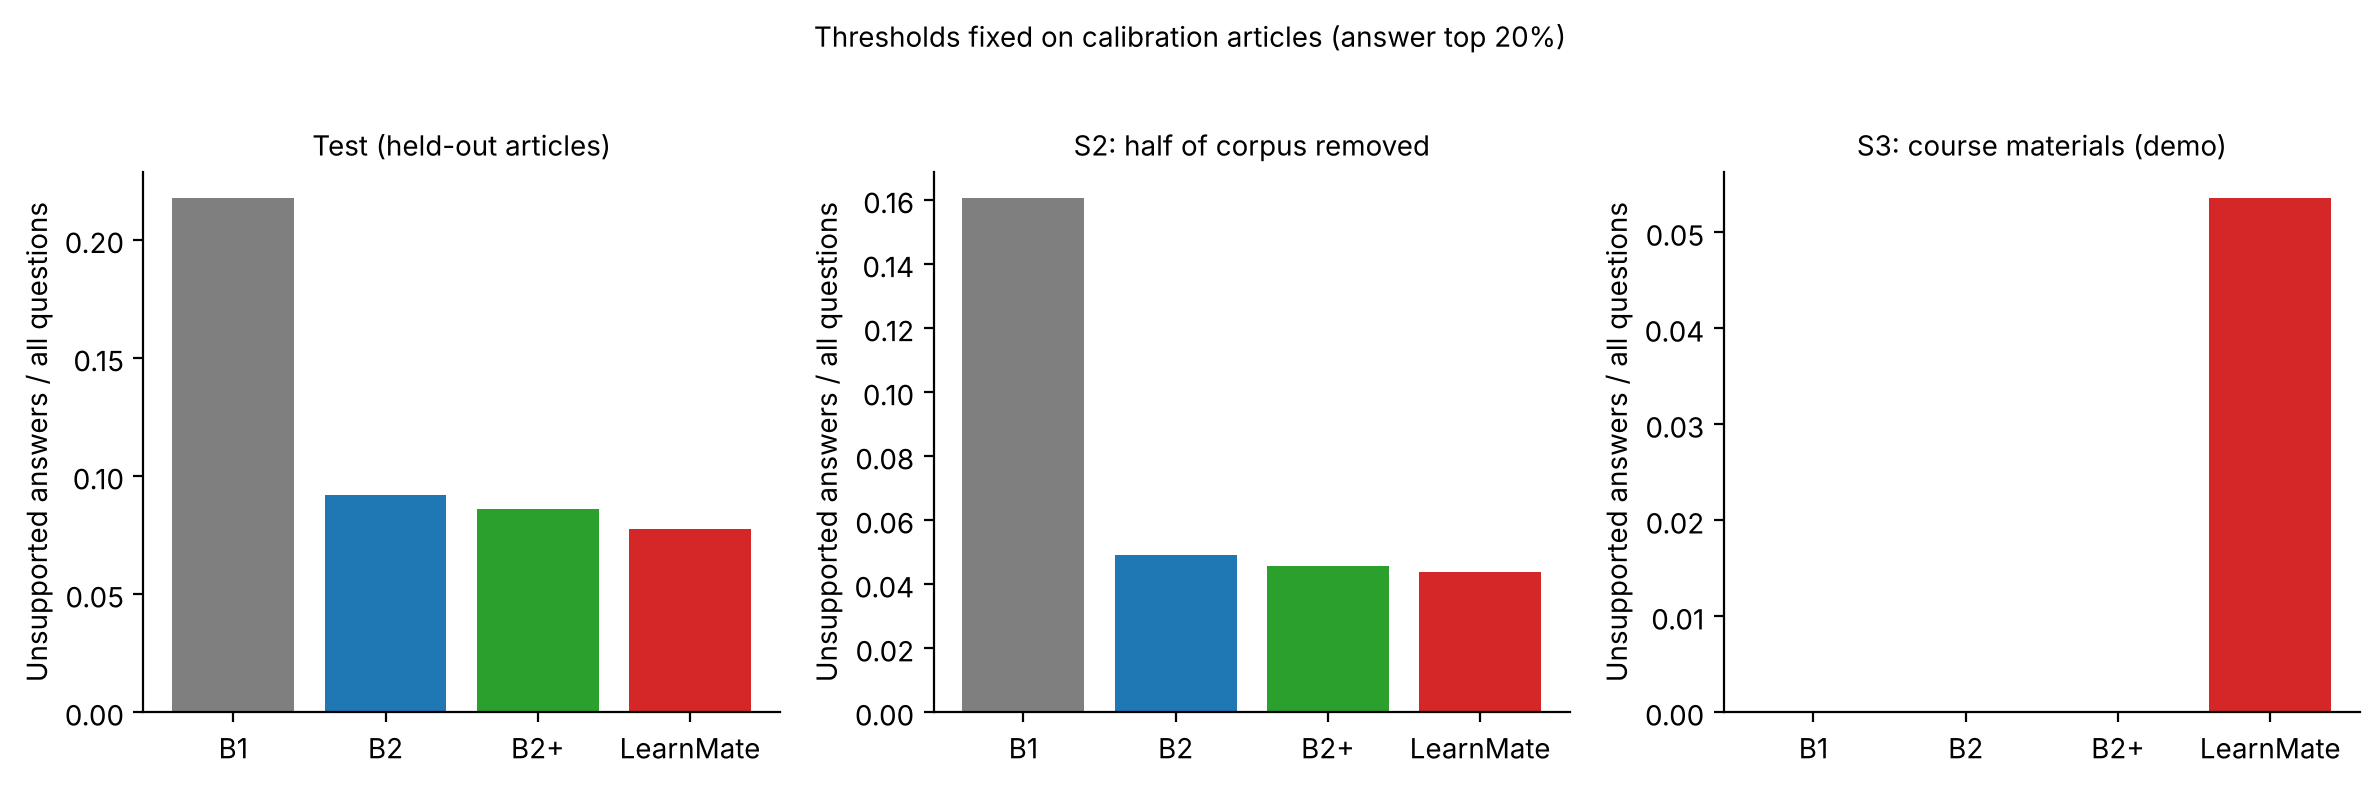

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8), sharey=False)
for a, (T, ttl) in zip(ax, [(T_main, "Test (held-out articles)"), (T_s2, "S2: half of corpus removed"), (T_c, "S3: course materials" + (" (demo)" if COURSE_IS_DEMO else ""))]):
    s = T[T.method.isin(COL)].set_index("method").loc[list(COL)]
    a.bar(range(len(s)), s.unsupported_answer_rate, color=list(COL.values())); a.set_xticks(range(len(s))); a.set_xticklabels(["B1", "B2", "B2+", "LearnMate"])
    a.set_title(ttl, fontsize=10); a.set_ylabel("Unsupported answers / all questions")
plt.suptitle(f"Thresholds fixed on calibration articles (answer top {int(COV_TARGET*100)}%)", y=1.02, fontsize=10); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figs/fig3_conditions.png", dpi=160, bbox_inches="tight"); plt.show()

## 8. Failure-case examples (held-out dev articles, LearnMate at its validation-chosen threshold)

In [ ]:
tau = TAU[LM]; conf = M_te[LM][0]; Zf = Z_te.copy(); Zf["conf"] = conf
txt = lambda sid: idx_te.sents[sid]["text"]
Zf["cited"] = [txt(s) for s in Zf.best_sid]
Zf["question"] = [Q_te[i]["question"] for i in Zf.index]
Zf["gold_answer"] = [Q_te[i]["answers"][0][0] if Q_te[i]["answers"] else "(unanswerable)" for i in Zf.index]
ans = Zf.conf >= tau
cases = []
a = Zf[ans & Zf.impossible].sort_values("conf", ascending=False).head(6).assign(failure="Answered an unanswerable question (confident)")
b = Zf[ans & ~Zf.impossible & (Zf.gold_b == 0)].sort_values("conf", ascending=False).head(4).assign(failure="Answerable but cited the wrong sentence")
c = Zf[~ans & (Zf.gold_b == 1)].sort_values("conf", ascending=False).head(4).assign(failure="Over-abstention (correct evidence was found)")
FAIL = pd.concat([a, b, c])[["failure", "question", "cited", "gold_answer", "conf", "ent_miss_p", "ent_miss_s", "agree_count"]]
FAIL["cited"] = FAIL.cited.str.slice(0, 220); FAIL.to_csv(f"{OUT_DIR}/failure_cases.csv", index=False)
for r in FAIL.itertuples():
    print(f"[{r.failure}] conf={r.conf:.2f}\n  Q: {r.question}\n  cited: {r.cited}\n  gold: {r.gold_answer}\n")

[Answered an unanswerable question (confident)] conf=0.90
  Q: What cannot be defined by bounding the time or space used the the algorithm?
  cited: Many important complexity classes can be defined by bounding the time or space used by the algorithm.
  gold: (unanswerable)

[Answered an unanswerable question (confident)] conf=0.89
  Q: In what year was Huguon built?
  cited: For many years, Sudan had an Islamist regime under the leadership of Hassan al-Turabi.
  gold: (unanswerable)

[Answered an unanswerable question (confident)] conf=0.88
  Q: What can not be achieved by ensuring different representations can transformed into each other efficiently?
  cited: This can be achieved by ensuring that different representations can be transformed into each other efficiently.
  gold: (unanswerable)

[Answered an unanswerable question (confident)] conf=0.86
  Q: Where is Biraben from?
  cited: According to Biraben, the plague was present somewhere in Europe in every year between 1346 and 1671

## 9. User-facing prototype

`LearnMate.ask(question)` returns either an **answer with a citation** (document, passage, sentence) or an **abstention with a reason**. On SQuAD-calibrated thresholds the tutor would abstain on almost every course question (Section 7.1 shows this), so the demo below uses a threshold fitted on the course pilot set at a 10% risk target — **in-sample, for demonstration only**. In a real deployment the instructor's labeled pilot questions would play this role of the full model; students can be shown the confidence and the reason.

In [ ]:
class LearnMate:
    def __init__(self, paras, tau=None, encoder=ENCODER):
        self.paras = paras; self.idx = Index(paras, encoder); self.tau = TAU[LM] if tau is None else tau
        self.cols = cols_of(ALL)
    def ask(self, question):
        q = dict(qid="live", pid=-1, article="live", question=question, impossible=False, answers=[])
        Z = score_questions(self.idx, [q]); conf = float(CAL[LM].predict_proba(Z[self.cols])[:, 1][0]); r = Z.iloc[0]
        s = self.idx.sents[int(r.best_sid)]; para = self.paras[self.idx.sents[int(r.best_sid)]["row"]]
        qa = analyze(question, self.idx); ptoks = self.idx.para_toks[s["row"]]
        missing = [e for e in qa["ent"] + qa["num"] if e not in ptoks]
        out = dict(confidence=round(conf, 3), citation=dict(document=para["article"], passage_id=para["pid"], sentence=s["text"]))
        if conf >= self.tau: out.update(status="ANSWER", answer=s["text"], reason="Evidence found in the course materials.")
        else:
            why = (f"The terms {missing} do not appear in the closest passage." if missing else
                   "The closest passage does not match the question closely enough to support an answer.")
            out.update(status="ABSTAIN", answer=None, reason=why + " Please ask the instructor or TA.")
        return out

conf_c, y_c = M_c[LM]; TAU_COURSE = pick_threshold(conf_c, y_c, 0.10)
if not np.isfinite(TAU_COURSE): TAU_COURSE = float(np.quantile(conf_c, 0.5))
print(f'course-domain threshold (in-sample, demo only): {TAU_COURSE:.3f}  vs SQuAD-calibrated: {TAU[LM]:.3f}')
tutor = LearnMate(P_c, tau=TAU_COURSE)
for q in ["What is the F1 score?", "Which dataset is used in Assignment 3?", "How is similarity between embeddings measured?",
          "What penalty applies if I submit my assignment late?", "Who won the 2018 FIFA World Cup?", "What is the weight of the midterm in the final grade?"]:
    r = tutor.ask(q); print(f"Q: {q}\n   -> {r['status']} (conf {r['confidence']})  {r['reason']}")
    if r["status"] == "ANSWER": print("   cites:", r["citation"]["document"], "| passage", r["citation"]["passage_id"], "|", r["citation"]["sentence"][:140])
    print()

course-domain threshold (in-sample, demo only): 0.589  vs SQuAD-calibrated: 0.563
Q: What is the F1 score?
   -> ANSWER (conf 0.66)  Evidence found in the course materials.
   cites: DL-501 demo | passage 12 | The F1 score is the harmonic mean of precision and recall.

Q: Which dataset is used in Assignment 3?
   -> ABSTAIN (conf 0.022)  The terms ['3'] do not appear in the closest passage. Please ask the instructor or TA.

Q: How is similarity between embeddings measured?
   -> ANSWER (conf 0.926)  Evidence found in the course materials.
   cites: DL-501 demo | passage 10 | Similarity between two embeddings is commonly measured with cosine similarity.

Q: What penalty applies if I submit my assignment late?
   -> ABSTAIN (conf 0.095)  The closest passage does not match the question closely enough to support an answer. Please ask the instructor or TA.

Q: Who won the 2018 FIFA World Cup?
   -> ABSTAIN (conf 0.001)  The terms ['fifa', 'world', 'cup', '2018'] do not appear in the closest

In [ ]:
# Optional web UI (needs: pip install gradio). Not launched by default. This cell was not executed when the notebook was produced.
try:
    import gradio as gr
    def _ui(question):
        r = tutor.ask(question)
        cite = f"{r['citation']['document']} / passage {r['citation']['passage_id']}: {r['citation']['sentence']}" if r["status"] == "ANSWER" else ""
        return r["status"] + f" (confidence {r['confidence']})", cite, r["reason"]
    demo = gr.Interface(fn=_ui, inputs=gr.Textbox(label="Ask about the course"),
                        outputs=[gr.Textbox(label="Status"), gr.Textbox(label="Answer (cited sentence)"), gr.Textbox(label="Why")], title="LearnMate")
    if LAUNCH_UI: demo.launch()
except ImportError:
    print("gradio not installed - skipping UI (pip install gradio)")

gradio not installed - skipping UI (pip install gradio)


## 10. Reproducibility package
Seeds, data hashes, package versions, and every table/figure are written to `outputs/`.

In [ ]:
import sklearn, scipy
env = dict(python=sys.version.split()[0], platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
           scipy=scipy.__version__, matplotlib=matplotlib.__version__, seed=SEED, quick_mode=QUICK, encoder=ENCODER.name, K_paragraphs=K_PARAS,
           risk_target=RISK_TARGET, data_sha256=DATA_HASHES, thresholds={k: v for k, v in TAU.items()},
           split_sizes=dict(reader_train_q=len(Q_rt), cal_fit_q=len(Q_cf), cal_val_q=len(Q_cv), test_q=len(Q_te), course_q=len(Q_c)),
           course_set="demo (author-written, unverified)" if COURSE_IS_DEMO else "user-provided")
json.dump(env, open(f"{OUT_DIR}/environment.json", "w"), indent=1, default=str)
open("requirements.txt", "w").write(f"numpy=={np.__version__}\npandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\nscipy=={scipy.__version__}\nmatplotlib=={matplotlib.__version__}\npypdf\n# optional: sentence-transformers gradio\n")
print(json.dumps(env, indent=1, default=str)[:1500])

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v726-x86_64-with-glibc2.39",
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "sklearn": "1.9.1",
 "scipy": "1.18.1",
 "matplotlib": "3.11.2",
 "seed": 42,
 "quick_mode": false,
 "encoder": "LSA-256 (frozen; stand-in for a Sentence-Transformer)",
 "K_paragraphs": 3,
 "risk_target": 0.3,
 "data_sha256": {
  "train-v2.0.json": "68dcfbb971bd3e96d5b46c7177b16c1a4e7d4bdef19fb204502738552dede002",
  "dev-v2.0.json": "80a5225e94905956a6446d296ca1093975c4d3b3260f1d6c8f68bc2ab77182d8"
 },
 "thresholds": {
  "B1 Dense sentence search": 0.822225558757782,
  "B2 RAG + reader confidence": 0.6056941332116653,
  "B2+ RAG + reader (support feats)": 0.632535825595675,
  "LearnMate (full)": 0.5629370299434497,
  "Abl: - agreement": 0.5583987700641608,
  "Abl: - support": 0.542241034596409,
  "Abl: - margin": 0.5459252121788997,
  "Abl: - retrieval": 0.5581471459546318,
  "Abl: - reader score": 0.5616457062455513,
  "Abl: reader only (calibrated)": 0.51559404

## 11. Limitations and honest scope
* **Encoder stand-in.** LSA is much weaker than a Sentence-Transformer; conclusions about the dense baseline (B1) must not be transferred to real Sentence-Transformers until `USE_SBERT=True` is run.
* **Sentence-level evidence, not generation.** No generative LLM is used; "supported" means the cited sentence contains the gold answer start. A small LLM reader/generator is a natural extension.
* **SQuAD artifact risk.** Entity-swap unanswerables make "entity missing from paragraph" informative; the course set (Section 7.1) is the check that this transfers, and the demo set is too small and not independently verified to settle it.
* **Strict gold matching.** Only the gold paragraph counts as support; a correct answer elsewhere in the corpus is counted as unsupported.
* **Weak evidence selector.** Even the best method answers wrongly or unsupportedly often; a trained neural reader/cross-encoder would likely change absolute numbers substantially.
* **Thresholds are set on SQuAD.** Under domain or base-rate shift the realized risk and coverage at a frozen threshold differ sharply from validation, as the stressed conditions show.
* **Novelty.** Related work (selective QA calibrators, answerability in RAG, evidence-based reliability alignment for RAG) overlaps with parts of this idea; see the report for positioning. Revise the paper title after your own full literature check.